In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Social_Network_Ads.csv')

In [3]:
df.head(2)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0


In [4]:
df.shape

(400, 5)

In [5]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [6]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [8]:
df['Gender'].value_counts()

Gender
Female    204
Male      196
Name: count, dtype: int64

<Axes: ylabel='count'>

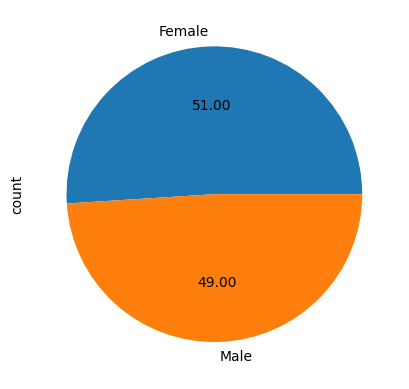

In [9]:
df['Gender'].value_counts().plot(kind='pie', autopct='%0.2f')

In [10]:
mask_male = df['Gender'] =='Male'
mask_female =df['Gender'] == 'Female'

In [11]:
mask_male

0       True
1       True
2      False
3      False
4       True
       ...  
395    False
396     True
397    False
398     True
399    False
Name: Gender, Length: 400, dtype: bool

In [12]:
df_male = df[mask_male]

In [13]:
df_male.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
4,15804002,Male,19,76000,0
5,15728773,Male,27,58000,0
8,15600575,Male,25,33000,0


In [14]:
df_male['Gender'].value_counts()

Gender
Male    196
Name: count, dtype: int64

In [15]:
df_female = df[mask_female]

In [16]:
df_female.head(2)

,User ID,Gender,Age,EstimatedSalary,Purchased
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0


In [17]:
df_female['Gender'].value_counts()

Gender
Female    204
Name: count, dtype: int64

In [18]:
df_male['EstimatedSalary'].sample(3)

116     75000
364    104000
368     71000
Name: EstimatedSalary, dtype: int64

In [19]:
df_male['EstimatedSalary'].mean()

67642.85714285714

In [20]:
df_female['EstimatedSalary'].mean()

71759.80392156863

In [21]:
df_male.head(1)

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0


In [22]:
df_male['Age'].mean()

36.86734693877551

In [23]:
df_female['Age'].mean()

38.411764705882355

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

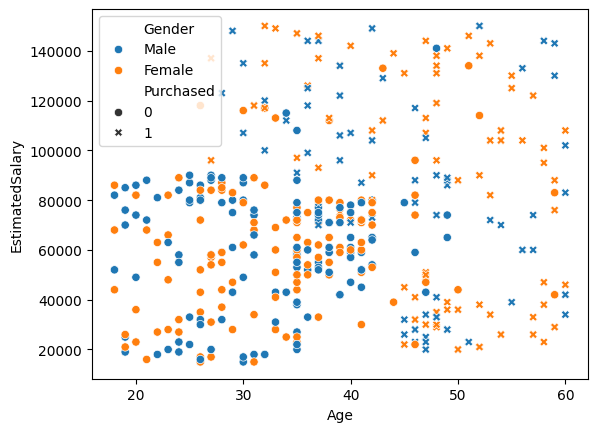

In [24]:
sns.scatterplot(x='Age', y='EstimatedSalary', data=df, hue='Gender', style='Purchased')

In [25]:
new = df.iloc[:,2:]

In [26]:
new.head(2)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0


In [27]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [28]:
df = df.drop('Gender', axis=1)

In [29]:
df.head(2)

,User ID,Age,EstimatedSalary,Purchased
0,15624510,19,19000,0
1,15810944,35,20000,0


In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train,X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1), df['Purchased'], test_size=0.3, random_state=0)

In [32]:
from sklearn.preprocessing import StandardScaler

In [33]:
X_train

,User ID,Age,EstimatedSalary
92,15809823,26,15000
223,15593715,60,102000
234,15619407,38,112000
232,15813113,40,107000
377,15800215,42,53000
...,...,...,...
323,15619465,48,30000
192,15779581,29,43000
117,15591433,36,52000
47,15776348,27,54000


In [34]:
y_train

92     0
223    1
234    0
232    1
377    0
      ..
323    1
192    0
117    0
47     0
172    0
Name: Purchased, Length: 280, dtype: int64

In [35]:
scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [36]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [37]:
X_train_scaled

array([[ 1.67118864e+00, -1.16317240e+00, -1.58497030e+00],
       [-1.38839503e+00,  2.17018137e+00,  9.30986724e-01],
       [-1.02465642e+00,  1.33054037e-02,  1.22017719e+00],
       [ 1.71776734e+00,  2.09385037e-01,  1.07558195e+00],
       [ 1.53516184e+00,  4.05464670e-01, -4.86046541e-01],
       [-1.05683679e+00, -2.80814046e-01, -3.12532264e-01],
       [ 3.23874887e-01,  9.93703570e-01, -8.33075096e-01],
       [ 1.46554862e+00,  9.93703570e-01,  1.85639620e+00],
       [ 1.53940914e+00,  1.33054037e-02,  1.24909623e+00],
       [ 1.38792217e+00, -8.69052946e-01,  2.26126285e+00],
       [-1.71742331e-01, -1.16317240e+00, -1.58497030e+00],
       [-7.91253235e-01,  2.17018137e+00, -8.04156050e-01],
       [-1.70199146e-01, -1.35925203e+00, -1.46929411e+00],
       [ 1.38112224e-01,  4.05464670e-01,  2.29018190e+00],
       [-3.55452132e-01,  7.97623937e-01,  7.57472446e-01],
       [-1.39831955e+00, -9.67092763e-01, -3.12532264e-01],
       [-9.79663379e-01,  1.11345220e-01

In [38]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)

In [40]:
X_train_scaled

,User ID,Age,EstimatedSalary
0,1.671189,-1.163172,-1.584970
1,-1.388395,2.170181,0.930987
2,-1.024656,0.013305,1.220177
3,1.717767,0.209385,1.075582
4,1.535162,0.405465,-0.486047
...,...,...,...
275,-1.023835,0.993704,-1.151185
276,1.243033,-0.869053,-0.775237
277,-1.420703,-0.182774,-0.514966
278,1.197261,-1.065133,-0.457127


In [41]:
X_test_scaled

array([[ 4.79637466e-01, -7.71013130e-01,  4.97201030e-01],
       [-5.57552735e-01,  1.33054037e-02, -5.72803680e-01],
       [ 1.20428316e+00, -2.80814046e-01,  1.50172476e-01],
       [ 6.60685627e-01, -7.71013130e-01,  2.65848661e-01],
       [-7.61380571e-01, -2.80814046e-01, -5.72803680e-01],
       [ 1.73038182e+00, -1.06513258e+00, -1.44037507e+00],
       [-1.15585546e+00, -6.72973313e-01, -1.58497030e+00],
       [-1.58490761e-01, -1.82774230e-01,  2.14558666e+00],
       [-3.63012323e-01, -1.94749093e+00, -5.22608478e-02],
       [-9.81178249e-01,  8.95663754e-01, -7.75237003e-01],
       [-3.33653583e-02, -7.71013130e-01, -6.01722726e-01],
       [ 1.53298156e+00, -9.67092763e-01, -4.28208449e-01],
       [ 1.15618958e+00, -8.47344130e-02, -4.28208449e-01],
       [-1.59372358e+00,  1.11345220e-01,  2.08010568e-01],
       [ 7.69572194e-01, -1.75141130e+00,  4.68281984e-01],
       [ 1.37792686e+00, -5.74933496e-01,  1.36477242e+00],
       [ 9.73881391e-01, -8.47344130e-02

In [43]:
np.round(X_train.describe(),2) 

,User ID,Age,EstimatedSalary
count,280.00,280.00,280.00
mean,15691781.70,37.86,69807.14
std,70759.61,10.22,34641.20
min,15569641.00,18.00,15000.00
25%,15628197.25,30.00,43000.00
50%,15694424.00,37.00,70500.00
75%,15751110.75,46.00,88000.00
max,15814816.00,60.00,150000.00


In [44]:
np.round(X_train_scaled.describe(), 2) 

,User ID,Age,EstimatedSalary
count,280.00,280.00,280.00
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-1.73,-1.95,-1.58
25%,-0.90,-0.77,-0.78
50%,0.04,-0.08,0.02
75%,0.84,0.80,0.53
max,1.74,2.17,2.32


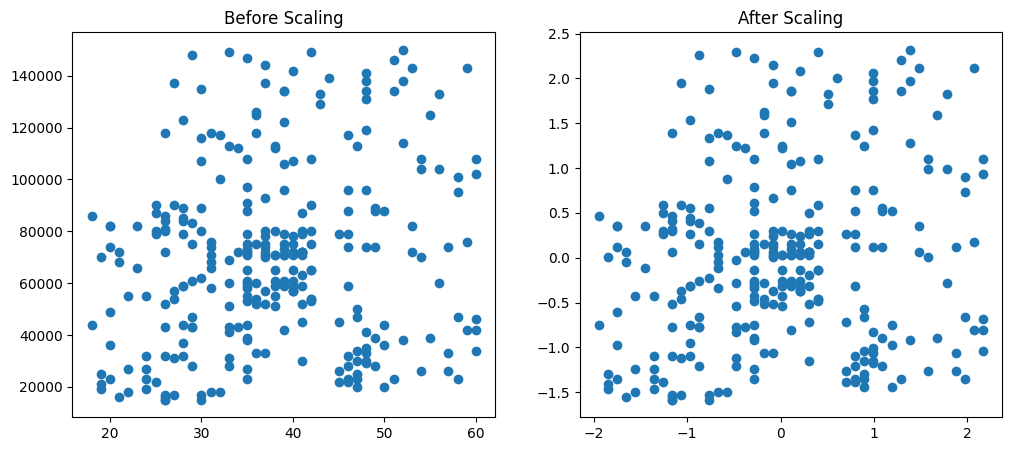

In [45]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize = (12,5))
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title("Before Scaling")
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'])
ax2.set_title("After Scaling")
plt.show()

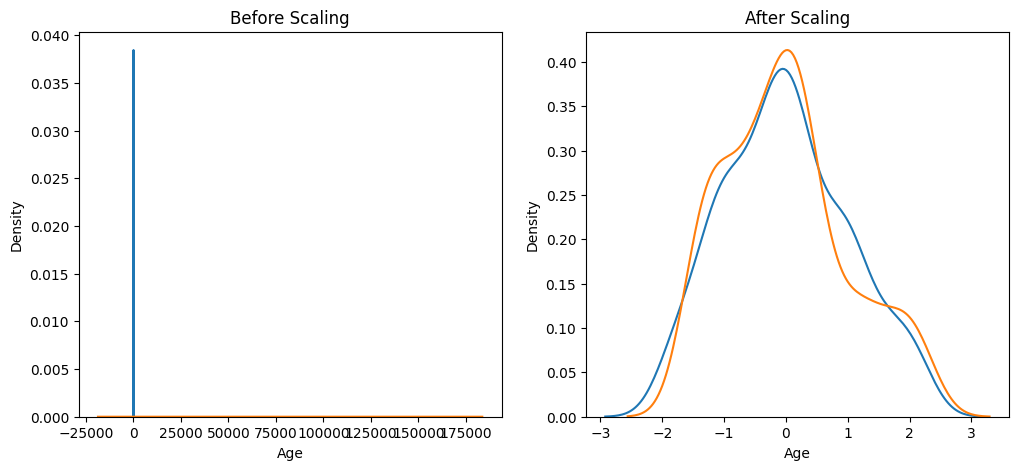

In [48]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))
ax1.set_title('Before Scaling')
ax2.set_title('After Scaling')
sns.kdeplot(X_train['Age'], ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax= ax1)
sns.kdeplot(X_train_scaled['Age'], ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax= ax2)
plt.show()


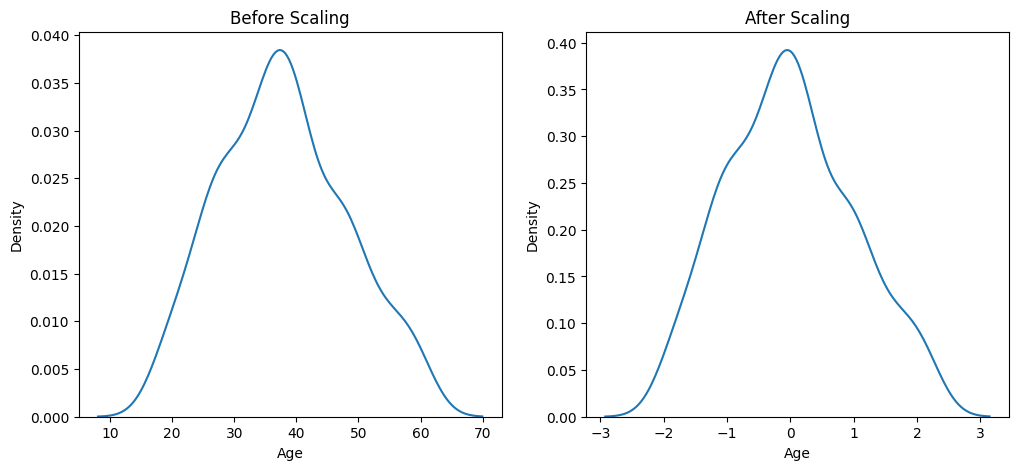

In [49]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12,5))
ax1.set_title('Before Scaling')
ax2.set_title('After Scaling')
sns.kdeplot(X_train['Age'], ax = ax1)
sns.kdeplot(X_train_scaled['Age'], ax = ax2)
plt.show()

In [50]:
from sklearn.linear_model import LogisticRegression as LOR

In [51]:
lr = LOR()

In [52]:
lr_scaled = LOR()

In [54]:
lr.fit(X_train,y_train)
lr_scaled.fit(X_train_scaled, y_train)

LogisticRegression()

In [55]:
y_pred = lr.predict(X_test)

In [56]:
y_pred_scaled = lr_scaled.predict(X_test)

In [57]:
from sklearn.metrics import accuracy_score

In [59]:
print("Actual Score: ", accuracy_score(y_test, y_pred))

Actual Score:  0.8666666666666667


In [60]:
print("Actual Score Scaled : ", accuracy_score(y_test, y_pred_scaled))

Actual Score Scaled :  0.6583333333333333
